# 07e VARIMA on the category totals

Every model so far looks at one series at a time. A vector model looks at several together, so a jump in FOODS can
inform the forecast for HOUSEHOLD. We try that on the three California category totals (each the sum of its
products among the 726), in thousands of units, since 07b showed that SARIMA on raw totals breaks down numerically.
The totals need one ordinary difference (05), so this is a VARMA on the differenced totals, with weekday dummies as
regressors, integrated back to levels: a VARIMA. It is a building block. We compare it with SARIMA on the same
totals and check with Granger tests whether the categories carry information about each other at all.

## Load

In [1]:
import ast, sys, time, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.varmax import VARMAX
from statsmodels.tsa.stattools import grangercausalitytests

import joblib
from joblib import Parallel, delayed

from config import ROOT, PROCESSED, TABLES, FIGS, EVAL_ORIGINS, CATEGORIES, FIG_STYLE, COLORS, FIT_DAYS
import ts_models as tm
from metrics import all_errors, mase_scale, holm_adjust
from forecasting import seasonal_naive

RERUN = False
plt.rcParams.update(FIG_STYLE)
written = []
UNIT = 1000

inp = tm.load_inputs()
ld = inp["long_df"]
tot = ld.groupby(["date", "category"])["sales"].sum().unstack()[CATEGORIES] / UNIT
st = pd.read_csv(TABLES / "stationarity_aggregates.csv").set_index("series")
agg = pd.read_csv(TABLES / "classical_orders.csv")
agg = agg[agg["level"] == "aggregate"].set_index("series")
print(st.loc[CATEGORIES, ["label", "d", "D"]].to_string())
print(f"\ntotals in thousands, {tot.index.min().date()} to {tot.index.max().date()}")
tot.describe().round(2)

                           label  d  D
series                                
FOODS      difference-stationary  1  0
HOBBIES    difference-stationary  1  0
HOUSEHOLD  difference-stationary  1  0

totals in thousands, 2011-01-29 to 2016-05-22


category,FOODS,HOBBIES,HOUSEHOLD
count,1941.00,1941.00,1941.00
mean,6.68,1.01,2.29
std,1.47,0.23,0.68
min,0.00,0.00,0.00
25%,5.65,0.88,1.83
50%,6.48,1.01,2.26
75%,7.62,1.16,2.66
max,11.86,1.89,4.34


## Differencing and weekday dummies

All three totals need d = 1 and no seasonal difference (05), so we take first differences. The weekly pattern is
left to six weekday dummies (Monday is the base). That keeps the model small: a weekly seasonal difference on top
would multiply the number of parameters.

In [2]:
D = int(st.loc[CATEGORIES, "d"].max())
assert D == 1 and st.loc[CATEGORIES, "D"].eq(0).all()

def weekdays(dates):
    dates = pd.DatetimeIndex(dates)
    return np.column_stack([(dates.dayofweek == k).astype(float) for k in range(1, 7)])

def train(o):
    x = tot[tot.index <= o].tail(FIT_DAYS)
    return x.to_numpy(), x.index

def varima_fc(Y, dates, p, q, h=28):
    """VARMA(p, q) on the first differences with weekday dummies, integrated back to levels."""
    dY, X = np.diff(Y, axis=0), weekdays(dates[1:])
    fd = pd.date_range(dates[-1] + pd.Timedelta(days=1), periods=h)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = VARMAX(dY, exog=X, order=(p, q), trend="c").fit(disp=False, maxiter=200)
    f = np.asarray(res.forecast(h, exog=weekdays(fd)))
    return Y[-1] + np.cumsum(f, axis=0), bool(res.mle_retvals.get("converged", True)), res

## A small order grid

At the warm-up origin we try VAR(1), VAR(2) and VARMA(1, 1). The weekly rhythm is already in the weekday dummies,
so the lags only have to carry what is left. We keep the lowest AICc and report BIC next to it. A first run also
tried lags up to 7 with a moving-average term; with three series VARMA(7, 1) has about a hundred parameters in a
21-state filter, and after two hours the grid had not finished, so we cut it to these three.

In [3]:
Y0, d0 = train(tm.VAL_ORIGINS[-1])
gpath = TABLES / "ts_varima_grid.csv"                # saved, because the three fits take about 20 minutes
if RERUN or not gpath.exists():
    grid = []
    for p, q in [(1, 0), (2, 0), (1, 1)]:
        t0 = time.time()
        try:
            _, ok, res = varima_fc(Y0, d0, p, q)
            grid.append({"p": p, "q": q, "aicc": res.aicc, "bic": res.bic, "converged": ok, "seconds": time.time() - t0})
        except Exception:
            grid.append({"p": p, "q": q, "aicc": np.nan, "bic": np.nan, "converged": False, "seconds": time.time() - t0})
    pd.DataFrame(grid).to_csv(gpath, index=False)
grid = pd.read_csv(gpath)
written.append(gpath)
P, Q = grid.loc[grid["aicc"].idxmin(), ["p", "q"]].astype(int)
print(f"chosen by AICc: p = {P}, q = {Q}; BIC would pick p = {grid.loc[grid['bic'].idxmin(), 'p']}, q = {grid.loc[grid['bic'].idxmin(), 'q']}")
grid.round(1)

chosen by AICc: p = 1, q = 1; BIC would pick p = 1, q = 1


,p,q,aicc,bic,converged,seconds
0,1,0,477.2,638.6,True,120.3
1,2,0,293.8,494.4,False,436.7
2,1,1,-16.9,183.6,False,586.3


## The backtest

VARIMA with the chosen order at all nine origins, against SARIMA on each total alone (the 07a orders for the totals,
fitted in thousands) and seasonal naive. Scores are in thousands of units.

In [4]:
def one(o):
    Y, dt = train(o)
    try:
        f, ok, _ = varima_fc(Y, dt, P, Q)
        return f, ok, False
    except Exception:
        return np.column_stack([seasonal_naive(Y[:, j]) for j in range(3)]), False, True

path = PROCESSED / "ts_varima_fits.joblib"          # the VARIMA fits take minutes each, so they are saved
if RERUN or not path.exists():
    t0 = time.time()
    joblib.dump(dict(zip(tm.ALL_ORIGINS, Parallel(n_jobs=len(tm.ALL_ORIGINS))(delayed(one)(o) for o in tm.ALL_ORIGINS))), path)
    print(f"VARIMA fits: {(time.time() - t0) / 60:.0f} min")
fits = joblib.load(path)

rows, fc_rows = [], []
for o in tm.ALL_ORIGINS:
    Y, dt = train(o)
    fd = pd.date_range(o + pd.Timedelta(days=1), periods=28)
    act = tot.reindex(fd)
    fv, ok_v, fb_v = fits[o]
    for j, c in enumerate(CATEGORIES):
        hist = tot.loc[tot.index <= o, c].to_numpy()
        so = ast.literal_eval(agg.loc[c, "sarima_order"]), ast.literal_eval(agg.loc[c, "sarima_sorder"])
        fs, ok_s, fb_s = tm.sarima_fc(Y[:, j], so[0], so[1])
        fcs = {"varima": (np.maximum(fv[:, j], 0), ok_v, fb_v), "sarima": (fs, ok_s, fb_s),
               "seasonal_naive": (seasonal_naive(Y[:, j]), True, False)}
        for m, (f, ok, fb) in fcs.items():
            rows.append({"series": c, "origin": o, "model": m, "converged": ok, "fallback": fb,
                         **all_errors(act[c].to_numpy(), f, mase_scale(hist))})
            fc_rows += [{"series": c, "origin": o, "date": d, "model": m, "forecast": v * UNIT, "actual": a * UNIT}
                        for d, v, a in zip(fd, f, act[c].to_numpy())]
res_t = pd.DataFrame(rows)
fc_t = pd.DataFrame(fc_rows)
fc_t.to_parquet(TABLES / "ts_varima_forecasts.parquet", index=False)
written.append(TABLES / "ts_varima_forecasts.parquet")
sc = tm.for_scoring(res_t).groupby(["series", "model"])[["rmse", "mae", "mape", "mase"]].mean().reset_index()
va = tm.for_tuning(res_t).groupby(["series", "model"])[["rmse", "mae", "mape", "mase"]].mean().reset_index()
table = sc.merge(va, on=["series", "model"], suffixes=("", "_validation"))
table.to_csv(TABLES / "ts_varima_scores.csv", index=False)
written.append(TABLES / "ts_varima_scores.csv")
print("fits that did not converge:", res_t.drop_duplicates(["origin", "model", "series"]).groupby("model")["converged"].apply(lambda s: int((~s).sum())).to_dict())
print("fell back to seasonal naive:", res_t.groupby("model")["fallback"].sum().astype(int).to_dict())
table.pivot(index="model", columns="series", values=["rmse", "mase"]).round(3)

fits that did not converge: {'sarima': 23, 'seasonal_naive': 0, 'varima': 27}
fell back to seasonal naive: {'sarima': 0, 'seasonal_naive': 0, 'varima': 0}


rmse                     mase                  
series          FOODS HOBBIES HOUSEHOLD  FOODS HOBBIES HOUSEHOLD
model                                                           
sarima          0.792   0.156     0.303  0.834   0.699     0.928
seasonal_naive  0.855   0.204     0.356  0.913   0.967     1.156
varima          0.777   0.151     0.294  0.837   0.678     0.891

In [5]:
old = pd.read_csv(TABLES / "sarima_totals_rescaled.csv")
old = old[old["scale"] == "thousands"].groupby("series")["mase"].mean()
print("SARIMA in thousands, mean MASE over the scored origins: here against 07b")
print(pd.DataFrame({"here": sc[sc["model"] == "sarima"].set_index("series")["mase"], "07b": old.reindex(CATEGORIES)}).round(3).to_string())

SARIMA in thousands, mean MASE over the scored origins: here against 07b
            here    07b
series                 
FOODS      0.834  0.834
HOBBIES    0.699  0.699
HOUSEHOLD  0.928  0.928


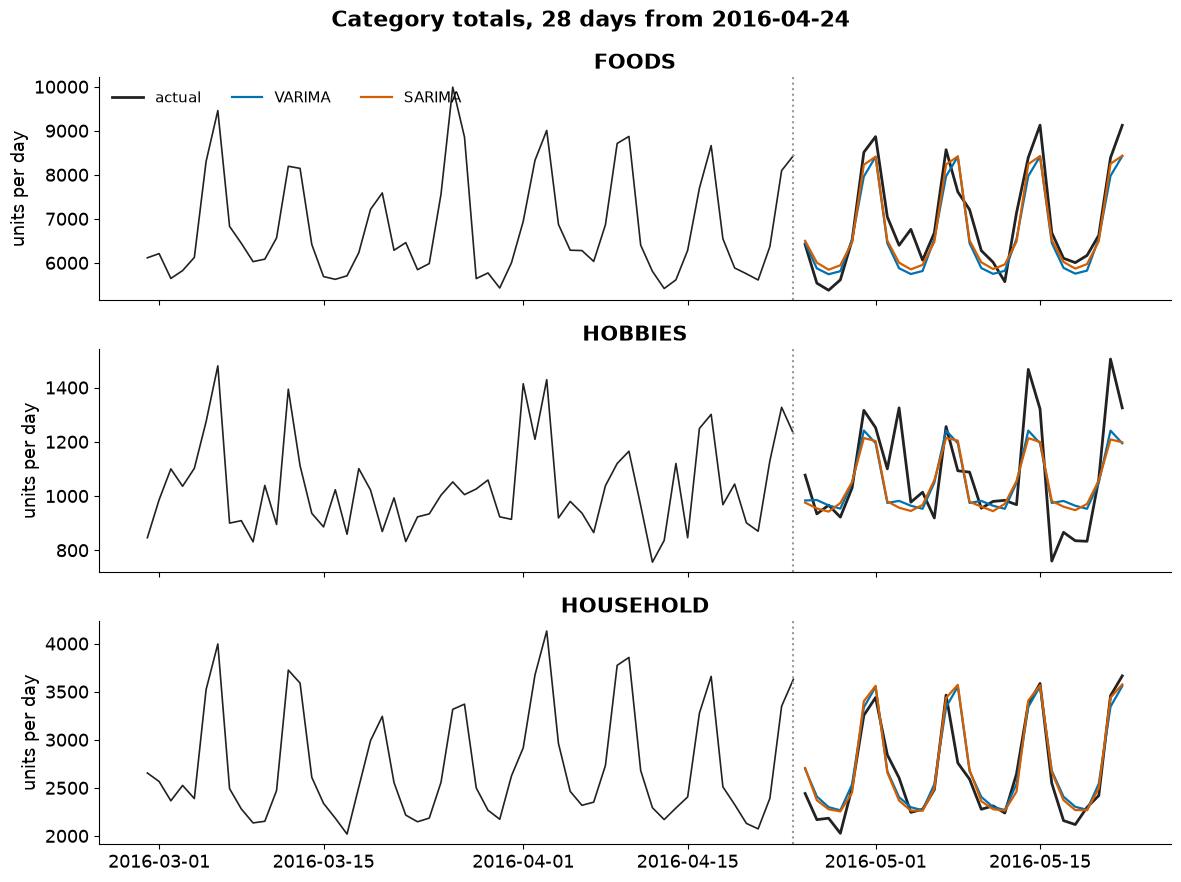

In [6]:
last = EVAL_ORIGINS[-1]
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, c in zip(axes, CATEGORIES):
    h = tot.loc[(tot.index > last - pd.Timedelta(days=56)) & (tot.index <= last), c]
    ax.plot(h.index, h * UNIT, color=COLORS["actual"], lw=1.2)
    g = fc_t[(fc_t["series"] == c) & (fc_t["origin"] == last)]
    ax.plot(g[g["model"] == "varima"]["date"], g[g["model"] == "varima"]["actual"], color=COLORS["actual"], lw=2, label="actual")
    for m, col in [("varima", "#0072B2"), ("sarima", COLORS["sarima"])]:
        x = g[g["model"] == m]
        ax.plot(x["date"], x["forecast"], color=col, lw=1.6, label=m.upper())
    ax.axvline(last, color="#999999", ls=":")
    ax.set_title(c)
    ax.set_ylabel("units per day")
axes[0].legend(ncol=3, frameon=False, loc="upper left")
fig.suptitle(f"Category totals, 28 days from {last.date()}", fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "ts_varima_totals.png")
written.append(FIGS / "ts_varima_totals.png")
plt.show()

## Granger tests

Does yesterday's FOODS total help forecast today's HOUSEHOLD total, beyond HOUSEHOLD's own past? We test every
ordered pair on the warm-up window's first differences, after removing the weekday means (otherwise the shared weekly
rhythm alone would look like a link). F-test at lags up to 7; the table keeps lag 7, and the p-values are
Holm-corrected over the six pairs.

In [7]:
dY = pd.DataFrame(np.diff(Y0, axis=0), columns=CATEGORIES, index=d0[1:])
dY = dY - dY.groupby(dY.index.dayofweek).transform("mean")
gr = []
for cause in CATEGORIES:
    for effect in CATEGORIES:
        if cause == effect:
            continue
        r = grangercausalitytests(dY[[effect, cause]], maxlag=7)
        gr.append({"cause": cause, "effect": effect, "f_stat_lag7": r[7][0]["ssr_ftest"][0], "p_lag7": r[7][0]["ssr_ftest"][1],
                   "smallest_p_lags_1_to_7": min(r[k][0]["ssr_ftest"][1] for k in range(1, 8))})
gr = pd.DataFrame(gr)
gr["p_holm"] = holm_adjust(gr["p_lag7"])
gr.to_csv(TABLES / "ts_granger.csv", index=False)
written.append(TABLES / "ts_granger.csv")
gr.round(4)

,cause,effect,f_stat_lag7,p_lag7,smallest_p_lags_1_to_7,p_holm
0,FOODS,HOBBIES,1.4639,0.1770,0.0017,0.885
1,FOODS,HOUSEHOLD,6.1567,0.0000,0.0000,0.000
2,HOBBIES,FOODS,1.0071,0.4248,0.0202,0.885
3,HOBBIES,HOUSEHOLD,1.2251,0.2863,0.1907,0.885
4,HOUSEHOLD,FOODS,0.9937,0.4345,0.0025,0.885
5,HOUSEHOLD,HOBBIES,1.4623,0.1776,0.0578,0.885


## What we found

The smallest grid was enough to decide. AICc and BIC agree on VARMA(1, 1) on the differenced totals, by a wide margin
(AICc -16.9 against 293.8 for VAR(2) and 477.2 for VAR(1)). Like most SARIMA fits on the totals, it stops before the
optimiser reports convergence at every origin (SARIMA: 23 of the 27 total-origin fits), but no forecast failed or
fell back.

VARIMA is a little better than SARIMA on two of the three totals. Over the six scored origins, in thousands of units,
its MASE is 0.678 against 0.699 for HOBBIES and 0.891 against 0.928 for HOUSEHOLD; for FOODS the two are level
(0.837 against 0.834), with VARIMA slightly ahead on RMSE (0.777 against 0.792) and SARIMA on MAE (0.583 against
0.585). Seasonal naive is clearly worse everywhere. On the validation origins VARIMA is ahead on all three. SARIMA
here reproduces 07b's rescaled numbers exactly (FOODS 0.834, HOBBIES 0.699, HOUSEHOLD 0.928).

The Granger tests say why the gain is small. After removing the weekday pattern, only one link survives the Holm
correction: the FOODS total helps forecast the HOUSEHOLD total (F = 6.16 at lag 7, p < 0.001). Four other pairs have
one lag with p below 0.06 on its own, but none is significant at lag 7 once the six tests are corrected. So VARIMA's
largest gain, on HOUSEHOLD, fits a link from FOODS; a plausible reason, which we have not tested, is that a busy food
week brings more shoppers into the store, and some of them buy household goods too.

VARIMA is a building block for the totals only. It cannot be used for the 726 products one at a time without
modelling hundreds of series together, so it is not a contender in 07h.

## What comes next

`07f_theta_prophet_autots` adds the last three single-model contenders on the 150 products.

In [8]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\tables\ts_varima_grid.csv 0 KB
outputs\tables\ts_varima_forecasts.parquet 27 KB
outputs\tables\ts_varima_scores.csv 2 KB
outputs\figures\ts_varima_totals.png 281 KB
outputs\tables\ts_granger.csv 1 KB
